# B2B SaaS Customer Churn Classification

### Problem Description

Customer Success teams have limited time to review accounts. If the team
can review only 10% of accounts, can a machine learning model identify
more churned accounts than the existing risk score?

This project uses a synthetic dataset of 50,000 B2B SaaS accounts.
The target is `is_churned`, where `1` indicates churn and `0` indicates no churn.

### Business Findings

- Enterprise accounts for 75.78% of total monthly recurring revenue (MRR)
  and 68.89% of the MRR associated with churned accounts.
- Starter has the highest churn rate at 2.28%.

### Validation Results

Recall@10% measures the share of all churned accounts found among
the top 10% of ranked accounts. Each method had a review budget of
1,000 accounts on the same validation set.

| Method | Churned accounts found | Recall@10% |
| --- | ---: | ---: |
| Random selection (expected) | 18.3 of 183 | 10.00% |
| Logistic regression (four account features) | 24 of 183 | 13.11% |
| Existing risk score | 34 of 183 | 18.58% |

The existing risk score found 10 more churned accounts than logistic
regression under the same review budget. A fixed random seed was used
to break score ties.

The held-out test set will be used for the final comparison after
model selection.

In [44]:
from pathlib import Path
import pandas as pd

## 0. CHECK DATA 

In [45]:
csv_path = next(Path("data").rglob("MP_Synthetics_50000_Rows.csv"))
df = pd.read_csv(csv_path)

df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'object'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')
display(df.head())

,customer_id,company_name,industry,country,company_size,account_manager,plan_tier,billing_cycle,monthly_recurring_revenue,signup_date,last_active_date,payment_status,active_seats_used,total_seats_allowed,support_tickets_30d,feature_adoption_rate,churn_risk_score,is_churned
0,CUST-1001,Pulse Net 944,HealthTech,Australia,11-50,Sarah Jenkins,Starter,Annual,49,2025-03-12,2026-02-18,Active,3,8,5,44%,Low,0
1,CUST-1002,Pulse Logic 332,CyberSecurity,USA,51-200,David Ross,Pro,Annual,499,2023-09-29,2026-02-25,Active,13,24,3,58%,Low,0
2,CUST-1003,Secure Flow 975,DevTools,India,1-10,David Ross,Starter,Monthly,79,2025-03-16,2026-02-19,Active,6,8,5,70%,Low,0
3,CUST-1004,Quantum Scale 657,EdTech,Singapore,51-200,Marcus Vance,Pro,Annual,249,2024-03-05,2026-02-22,Active,34,39,2,90%,Low,0
4,CUST-1005,Quantum Sphere 308,E-Commerce,Germany,1-10,Aisha Khan,Starter,Monthly,129,2025-02-28,2026-02-22,Active,8,9,3,93%,Low,0


In [46]:
print("Rows and columns:", df.shape)
print("Duplicate customer IDs:", df["customer_id"].duplicated().sum())

display(df.head())
display(df["is_churned"].value_counts(dropna=False))
print("Duplicate customer IDs:", df["customer_id"].duplicated().sum())

columns = ["plan_tier", "monthly_recurring_revenue", "is_churned"]
display(df[columns].isna().sum())

Rows and columns: (50000, 18)
Duplicate customer IDs: 0


,customer_id,company_name,industry,country,company_size,account_manager,plan_tier,billing_cycle,monthly_recurring_revenue,signup_date,last_active_date,payment_status,active_seats_used,total_seats_allowed,support_tickets_30d,feature_adoption_rate,churn_risk_score,is_churned
0,CUST-1001,Pulse Net 944,HealthTech,Australia,11-50,Sarah Jenkins,Starter,Annual,49,2025-03-12,2026-02-18,Active,3,8,5,44%,Low,0
1,CUST-1002,Pulse Logic 332,CyberSecurity,USA,51-200,David Ross,Pro,Annual,499,2023-09-29,2026-02-25,Active,13,24,3,58%,Low,0
2,CUST-1003,Secure Flow 975,DevTools,India,1-10,David Ross,Starter,Monthly,79,2025-03-16,2026-02-19,Active,6,8,5,70%,Low,0
3,CUST-1004,Quantum Scale 657,EdTech,Singapore,51-200,Marcus Vance,Pro,Annual,249,2024-03-05,2026-02-22,Active,34,39,2,90%,Low,0
4,CUST-1005,Quantum Sphere 308,E-Commerce,Germany,1-10,Aisha Khan,Starter,Monthly,129,2025-02-28,2026-02-22,Active,8,9,3,93%,Low,0


is_churned
0    49084
1      916
Name: count, dtype: int64

Duplicate customer IDs: 0


plan_tier                    0
monthly_recurring_revenue    0
is_churned                   0
dtype: int64

In [47]:
tier_summary = (
    df.assign(
        churned_mrr=df["monthly_recurring_revenue"].where(
            df["is_churned"].eq(1), 0
        )
    )
    .groupby("plan_tier")
    .agg(
        accounts=("customer_id", "size"),
        churned_accounts=("is_churned", "sum"),
        total_mrr=("monthly_recurring_revenue", "sum"),
        churned_mrr=("churned_mrr", "sum"),
    )
)

tier_summary["churn_rate_pct"] = (
    100 * tier_summary["churned_accounts"] / tier_summary["accounts"]
)

display(tier_summary.sort_values("total_mrr", ascending=False).round(2))
display(df[columns].isna().sum())

,accounts,churned_accounts,total_mrr,churned_mrr,churn_rate_pct
plan_tier,,,,,
Enterprise,5051,57,25211067,272849,1.13
Pro,14941,174,5390159,62676,1.16
Starter,30008,685,2666682,60515,2.28


plan_tier                    0
monthly_recurring_revenue    0
is_churned                   0
dtype: int64

In [48]:
tier_summary["mrr_share_pct"] = (
    100 * tier_summary["total_mrr"] / tier_summary["total_mrr"].sum()
)

display(tier_summary[["mrr_share_pct", "churn_rate_pct"]].round(2))

,mrr_share_pct,churn_rate_pct
plan_tier,,
Enterprise,75.78,1.13
Pro,16.20,1.16
Starter,8.02,2.28


In [49]:
tier_summary["churned_mrr_share_pct"] = (
    100 * tier_summary["churned_mrr"] / tier_summary["churned_mrr"].sum()
)

display(
    tier_summary[["churned_mrr", "churned_mrr_share_pct"]]
    .sort_values("churned_mrr", ascending=False)
    .round(2)
)

,churned_mrr,churned_mrr_share_pct
plan_tier,,
Enterprise,272849,68.89
Pro,62676,15.83
Starter,60515,15.28


## 1. EDA

In [61]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=11, stratify=df["is_churned"]
)
df_train, df_val = train_test_split(
    df_full_train,
    test_size=0.25,
    random_state=11,
    stratify=df_full_train["is_churned"],
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train['is_churned'].values
y_val = df_val['is_churned'].values
y_test = df_test['is_churned'].values

del df_train['is_churned']
del df_val['is_churned']
del df_test['is_churned']

In [62]:
account_features = [
    "industry",
    "company_size",
    "plan_tier",
    "billing_cycle",
]

target = "is_churned"

In [63]:
from sklearn import set_config
set_config(display="text")

In [64]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(df_train[account_features].to_dict(orient="records"))
X_val = dv.transform(df_val[account_features].to_dict(orient="records"))

model = LogisticRegression()
model.fit(X_train, y_train)

y_val_scores = model.predict_proba(X_val)[:, 1]
print(y_val_scores[:5])

[0.01244875 0.01158652 0.02209114 0.02095884 0.01336144]


In [65]:
val_dict = df_val[account_features].to_dict(orient='records')
X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[:, 1]
churn_decision = (y_pred >= 0.5)
(y_val == churn_decision).mean()

np.float64(0.9817)

In [66]:
print("Predicted churn:", (y_val_scores >= 0.5).sum())
print("Actual churn:", y_val.sum())

Predicted churn: 0
Actual churn: 183


## 2. CHURN

In [67]:
from math import ceil

ranking = pd.DataFrame({"score": y_val_scores, "is_churned": y_val})
k = ceil(len(ranking) * 0.10)

top_accounts = (
    ranking.sample(frac=1, random_state=11)
    .sort_values("score", ascending=False, kind="stable")
    .head(k)
)

caught = top_accounts["is_churned"].sum()
total_churned = ranking["is_churned"].sum()

print(f"Accounts reviewed: {k}")
print(f"Churned accounts found: {caught}/{total_churned}")
print(f"Recall@10%: {caught / total_churned:.2%}")

Accounts reviewed: 1000
Churned accounts found: 24/183
Recall@10%: 13.11%


In [68]:
df_val["churn_risk_score"].value_counts(dropna=False)

churn_risk_score
Low       9929
Medium      69
High         2
Name: count, dtype: int64

In [69]:
legacy_scores = df_val["churn_risk_score"].map({
    "High": 2,
    "Medium": 1,
    "Low": 0,
})
assert legacy_scores.notna().all(), "Unexpected risk category"

legacy_ranking = pd.DataFrame({
    "score": legacy_scores.to_numpy(),
    "is_churned": y_val,
})

legacy_top = (
    legacy_ranking.sample(frac=1, random_state=11)
    .sort_values("score", ascending=False, kind="stable")
    .head(k)
)

legacy_caught = legacy_top["is_churned"].sum()
print(f"Legacy churned accounts found: {legacy_caught}/{total_churned}")
print(f"Legacy Recall@10%: {legacy_caught / total_churned:.2%}")

Legacy churned accounts found: 34/183
Legacy Recall@10%: 18.58%


## 4.Classification

In [70]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=2,
    random_state=11,
    n_jobs=-1,
)

rf_model.fit(X_train, y_train)
rf_val_scores = rf_model.predict_proba(X_val)[:, 1]

display(rf_val_scores)

array([0.01255606, 0.00836401, 0.03290641, ..., 0.00381254, 0.01795306,
       0.01255606], shape=(10000,))

In [71]:
from sklearn.metrics import average_precision_score

rf_ranking = pd.DataFrame({"score": rf_val_scores, "is_churned": y_val})

rf_top = (
    rf_ranking.sample(frac=1, random_state=11)
    .sort_values("score", ascending=False, kind="stable")
    .head(k)
)

rf_caught = rf_top["is_churned"].sum()

print(f"Churned accounts found: {rf_caught}/{total_churned}")
print(f"Random Forest Recall@10%: {rf_caught / total_churned:.2%}")
print(f"Random Forest Average Precision: {average_precision_score(y_val, rf_val_scores):.4f}")

Churned accounts found: 20/183
Random Forest Recall@10%: 10.93%
Random Forest Average Precision: 0.0214


## 5.Logistic Regression

In [72]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

def make_usage_records(frame):
    features = frame[account_features].copy()

    adoption = frame["feature_adoption_rate"].astype("string").str.strip()
    features["feature_adoption_rate"] = (
        pd.to_numeric(adoption.str.rstrip("%"), errors="coerce") / 100
    )
    features["support_tickets_30d"] = frame["support_tickets_30d"]

    seat_limit = frame["total_seats_allowed"].where(
        frame["total_seats_allowed"] > 0
    )
    features["seat_utilization"] = frame["active_seats_used"] / seat_limit

    return features.to_dict(orient="records")

usage_dv = DictVectorizer(sparse=False)
X_train_usage = usage_dv.fit_transform(make_usage_records(df_train))
X_val_usage = usage_dv.transform(make_usage_records(df_val))

# Fit missing-value replacements on train only.
from sklearn.impute import SimpleImputer

usage_imputer = SimpleImputer(strategy="median")
X_train_usage = usage_imputer.fit_transform(X_train_usage)
X_val_usage = usage_imputer.transform(X_val_usage)

usage_model = LogisticRegression()
usage_model.fit(X_train_usage, y_train)
usage_val_scores = usage_model.predict_proba(X_val_usage)[:, 1]

In [73]:
usage_ranking = pd.DataFrame({
    "score": usage_val_scores,
    "is_churned": y_val,
})

usage_top = (
    usage_ranking.sample(frac=1, random_state=11)
    .sort_values("score", ascending=False, kind="stable")
    .head(k)
)

usage_caught = usage_top["is_churned"].sum()

print(f"Churned accounts found: {usage_caught}/{total_churned}")
print(f"Recall@10%: {usage_caught / total_churned:.2%}")
print(f"Average Precision: {average_precision_score(y_val, usage_val_scores):.4f}")

Churned accounts found: 65/183
Recall@10%: 35.52%
Average Precision: 0.0787


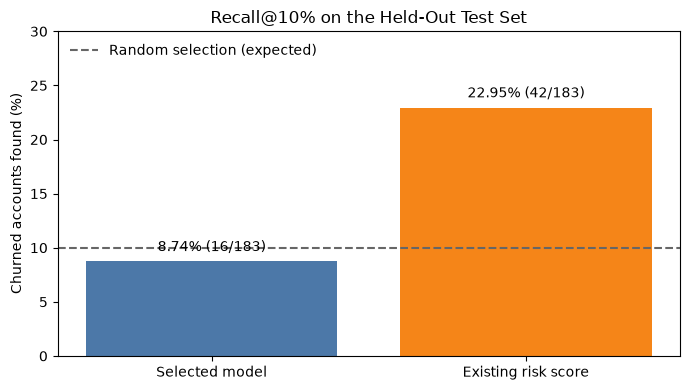

In [ ]:
methods = ["Selected model", "Existing risk score"]
caught = [16, 42]
total_churned = 183
recall_pct = [100 * count / total_churned for count in caught]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(methods, recall_pct, color=["#4C78A8", "#F58518"])

ax.bar_label(
    bars,
    labels=[
        f"{pct:.2f}% ({count}/{total_churned})"
        for pct, count in zip(recall_pct, caught)
    ],
    padding=5,
)
ax.axhline(10, color="#666666", linestyle="--", label="Random selection (expected)")
ax.set_title("Recall@10% on the Held-Out Test Set")
ax.set_ylabel("Churned accounts found (%)")
ax.set_ylim(0, 30)
ax.legend(loc="upper left", frameon=False)

plt.tight_layout()
plt.show()

On the held-out test set, the existing risk score identified 42 of 183 churned accounts among the 1,000 accounts reviewed, compared with 16 for the selected model. Recall@10% was 22.95% for the existing score and 8.74% for the selected model. The existing score also achieved higher average precision (0.0763 vs. 0.0193).

## 6.TEST SET

In [ ]:
X_test_usage = usage_dv.transform(make_usage_records(df_test))
X_test_usage = usage_imputer.transform(X_test_usage)
test_scores = usage_model.predict_proba(X_test_usage)[:, 1]

X_test = dv.transform(df_test[account_features].to_dict("records"))
selected_model = rf_model 
test_scores = selected_model.predict_proba(X_test)[:, 1]

In [78]:
legacy_test_scores = df_test["churn_risk_score"].map(
    {"High": 2, "Medium": 1, "Low": 0}
)
assert legacy_test_scores.notna().all(), "Unexpected risk category"

k_test = ceil(len(y_test) * 0.10)
total_test_churned = y_test.sum()

for name, scores in {
    "Selected model": test_scores,
    "Existing risk score": legacy_test_scores.to_numpy(),
}.items():
    ranking = pd.DataFrame({"score": scores, "is_churned": y_test})
    top_accounts = (
        ranking.sample(frac=1, random_state=11)
        .sort_values("score", ascending=False, kind="stable")
        .head(k_test)
    )

    caught = top_accounts["is_churned"].sum()
    print(
        f"{name}: {caught}/{total_test_churned} churned accounts found "
        f"among {k_test} reviewed | Recall@10%: {caught / total_test_churned:.2%} "
        f"| AP: {average_precision_score(y_test, scores):.4f}"
    )

Selected model: 16/183 churned accounts found among 1000 reviewed | Recall@10%: 8.74% | AP: 0.0193
Existing risk score: 42/183 churned accounts found among 1000 reviewed | Recall@10%: 22.95% | AP: 0.0763
